#  Part A: Data Understanding and Preprocessing #

1. Load the dataset and explore:
   
○ Display first 10 rows.

○ Plot temperature trends over time.

○ Check for missing values.

--- First 10 Rows ---


,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),Daily Summary
0,2006-04-01 00:00:00.000 +0200,Partly Cloudy,rain,9.472222,7.388889,0.89,14.1197,251.0,15.8263,0.0,1015.13,Partly cloudy throughout the day.
1,2006-04-01 01:00:00.000 +0200,Partly Cloudy,rain,9.355556,7.227778,0.86,14.2646,259.0,15.8263,0.0,1015.63,Partly cloudy throughout the day.
2,2006-04-01 02:00:00.000 +0200,Mostly Cloudy,rain,9.377778,9.377778,0.89,3.9284,204.0,14.9569,0.0,1015.94,Partly cloudy throughout the day.
3,2006-04-01 03:00:00.000 +0200,Partly Cloudy,rain,8.288889,5.944444,0.83,14.1036,269.0,15.8263,0.0,1016.41,Partly cloudy throughout the day.
4,2006-04-01 04:00:00.000 +0200,Mostly Cloudy,rain,8.755556,6.977778,0.83,11.0446,259.0,15.8263,0.0,1016.51,Partly cloudy throughout the day.
5,2006-04-01 05:00:00.000 +0200,Partly Cloudy,rain,9.222222,7.111111,0.85,13.9587,258.0,14.9569,0.0,1016.66,Partly cloudy throughout the day.
6,2006-04-01 06:00:00.000 +0200,Partly Cloudy,rain,7.733333,5.522222,0.95,12.3648,259.0,9.9820,0.0,1016.72,Partly cloudy throughout the day.
7,2006-04-01 07:00:00.000 +0200,Partly Cloudy,rain,8.772222,6.527778,0.89,14.1519,260.0,9.9820,0.0,1016.84,Partly cloudy throughout the day.
8,2006-04-01 08:00:00.000 +0200,Partly Cloudy,rain,10.822222,10.822222,0.82,11.3183,259.0,9.9820,0.0,1017.37,Partly cloudy throughout the day.
9,2006-04-01 09:00:00.000 +0200,Partly Cloudy,rain,13.772222,13.772222,0.72,12.5258,279.0,9.9820,0.0,1017.22,Partly cloudy throughout the day.



--- Missing Values ---
Formatted Date                0
Summary                       0
Precip Type                 517
Temperature (C)               0
Apparent Temperature (C)      0
Humidity                      0
Wind Speed (km/h)             0
Wind Bearing (degrees)        0
Visibility (km)               0
Loud Cover                    0
Pressure (millibars)          0
Daily Summary                 0
dtype: int64


C:\Users\Nimish\AppData\Local\Temp\ipykernel_32336\1346676684.py:18: FutureWarning: In a future version of pandas, parsing datetimes with mixed time zones will raise an error unless `utc=True`. Please specify `utc=True` to opt in to the new behaviour and silence this warning. To create a `Series` with mixed offsets and `object` dtype, please use `apply` and `datetime.datetime.strptime`
  plt.plot(pd.to_datetime(df['Formatted Date']), df['Temperature (C)'], label='Temperature', color='orange')


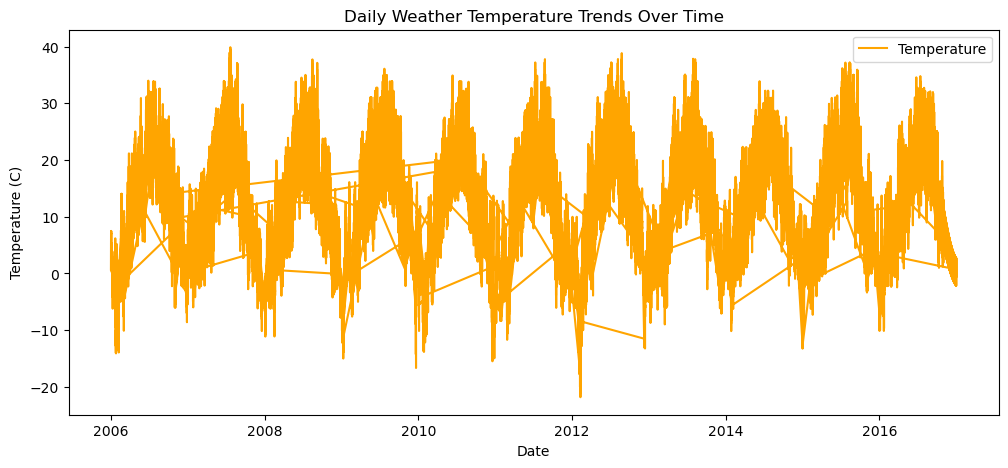

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset 
df = pd.read_csv('weatherHistory.csv')

# Display the first 10 rows
print("--- First 10 Rows ---")
display(df.head(10))

# Check for missing values
print("\n--- Missing Values ---")
print(df.isnull().sum())

# Plot temperature trends over time 
plt.figure(figsize=(12, 5))
plt.plot(pd.to_datetime(df['Formatted Date']), df['Temperature (C)'], label='Temperature', color='orange')
plt.title('Daily Weather Temperature Trends Over Time')
plt.xlabel('Date')
plt.ylabel('Temperature (C)')
plt.legend()
plt.show()

2. Preprocess the data:
   
○ Handle missing values (impute/remove).

○ Normalize values using MinMaxScaler (so RNN converges faster).

○ Create input sequences:

■ Use past 7–14 days’ weather data (temperature, humidity, wind speed) as input.

■ Target: next day’s temperature.

○ Split dataset into train, validation, and test sets. ###

In [2]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# Handle missing values using forward fill
df = df.ffill()

# Select relevant features 
features = ['Temperature (C)', 'Humidity', 'Wind Speed (km/h)', 'Pressure (millibars)']
data = df[features].values

# Normalize values using MinMaxScaler (between 0 and 1)
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(data)

# Function to create input sequences (using past 14 timestamps to predict next)
def create_sequences(dataset, seq_length):
    X, y = [], []
    for i in range(len(dataset) - seq_length):
        X.append(dataset[i:(i + seq_length)])
        y.append(dataset[i + seq_length, 0]) # Index 0 is Temperature (C) (target)
    return np.array(X), np.array(y)

SEQ_LENGTH = 14 # Window size
X, y = create_sequences(scaled_data, SEQ_LENGTH)

# Split dataset into train (70%), validation (15%), and test (15%) sets
train_size = int(len(X) * 0.7)
val_size = int(len(X) * 0.15)

X_train, y_train = X[:train_size], y[:train_size]
X_val, y_val = X[train_size:train_size+val_size], y[train_size:train_size+val_size]
X_test, y_test = X[train_size+val_size:], y[train_size+val_size:]

print("Train shape:", X_train.shape, y_train.shape)
print("Validation shape:", X_val.shape, y_val.shape)
print("Test shape:", X_test.shape, y_test.shape)

Train shape: (67507, 14, 4) (67507,)
Validation shape: (14465, 14, 4) (14465,)
Test shape: (14467, 14, 4) (14467,)


### Observations and Explanation:
* **Missing Value Handling:** Used `df.ffill()` (forward fill) to handle any missing values in the dataset, ensuring continuity in the time-series data.
* **Feature Selection:** Selected relevant numerical features (`Temperature (C)`, `Humidity`, `Wind Speed (km/h)`, `Pressure (millibars)`) for predicting future temperature.
* **Normalization:** Applied `MinMaxScaler` to scale all feature values between 0 and 1, which helps neural networks and RNN models converge much faster and more efficiently.
* **Sequence Creation:** Created sliding windows of past 14 timestamps (`SEQ_LENGTH = 14`) to predict the temperature of the next timestamp.
* **Dataset Splitting:** Divided the processed data into Training (70%), Validation (15%), and Testing (15%) sets to properly train and evaluate the model.


# Part B: RNN Model Development

3. Build a SimpleRNN model using TensorFlow/Keras:

○ Input layer (with shape = sequence length × number of features).

○ SimpleRNN layer (e.g., 32–64 units).

○ Dropout layer (optional, to avoid overfitting).

○ Dense layer with 1 unit (linear activation for regression).

In [3]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

# Build the SimpleRNN model architecture
model = Sequential([
    SimpleRNN(50, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2])),
    Dense(1)
])

print("RNN Model built successfully!")

RNN Model built successfully!


C:\Users\Nimish\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


4. Compile the model:
   
○ Loss: Mean Squared Error (MSE).

○ Optimizer: Adam.

○ Metrics: Mean Absolute Error (MAE).

In [4]:
# Compile the model with MSE loss, Adam optimizer, and MAE metric
model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mae'])

# Display model summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 50)             │         2,750 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,801 (10.94 KB)

 Trainable params: 2,801 (10.94 KB)

 Non-trainable params: 0 (0.00 B)

5. Train the model on training data:
   
○ Batch size: 32

○ Epochs: 50–100

○ Use validation data to monitor performance.

○ Plot training vs validation loss curves.

In [5]:
# Train the model using training data and monitor performance with validation data
history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/50
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 19s 8ms/step - loss: 9.0072e-04 - mae: 0.0203 - val_loss: 6.2478e-04 - val_mae: 0.0194
Epoch 2/50
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 15s 7ms/step - loss: 6.2284e-04 - mae: 0.0170 - val_loss: 3.8754e-04 - val_mae: 0.0131
Epoch 3/50
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 16s 7ms/step - loss: 5.9030e-04 - mae: 0.0163 - val_loss: 5.3970e-04 - val_mae: 0.0172
Epoch 4/50
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 15s 7ms/step - loss: 5.7514e-04 - mae: 0.0160 - val_loss: 3.9355e-04 - val_mae: 0.0135
Epoch 5/50
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 15s 7ms/step - loss: 5.6116e-04 - mae: 0.0157 - val_loss: 3.8463e-04 - val_mae: 0.0134
Epoch 6/50
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - loss: 5.5063e-04 - mae: 0.0155 - val_loss: 4.2672e-04 - val_mae: 0.0145
Epoch 7/50
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 15s 7ms/step - loss: 5.3989e-04 - mae: 0.0153 - val_loss: 3.5393e-04 - val_mae: 0.0126
Epoch 8/50
2110/2110 ━━━━━━━━━━━━━━━━━━━━ 15s 7ms/step - loss: 5.3570e-04 - mae: 0.0152 - val_los

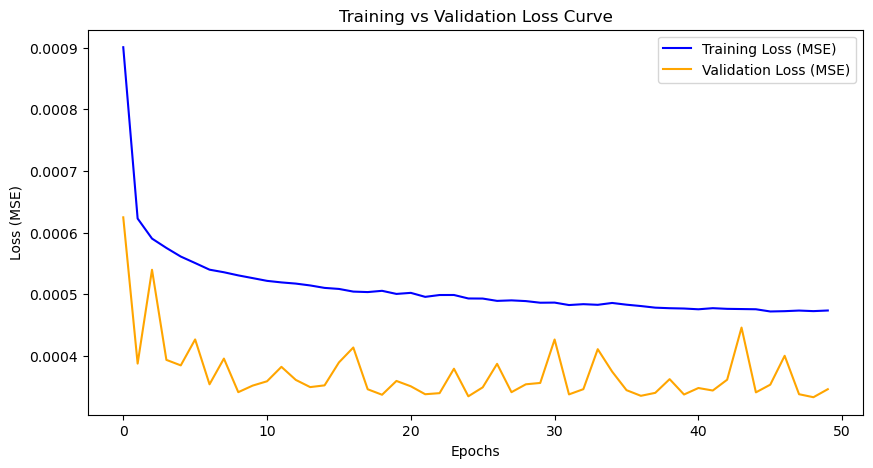

In [6]:
import matplotlib.pyplot as plt

# Plotting the training and validation loss curves
plt.figure(figsize=(10, 5))
plt.plot(history.history['loss'], label='Training Loss (MSE)', color='blue')
plt.plot(history.history['val_loss'], label='Validation Loss (MSE)', color='orange')
plt.title('Training vs Validation Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.show()

### Observations and Explanation:
* **Model Architecture:** A Sequential model was successfully built using a `SimpleRNN` layer with 50 units and `ReLU` activation, followed by a `Dense` output layer for regression (temperature prediction.
  
* **Compilation & Metrics:** The model was compiled using the `Adam` optimizer, `Mean Squared Error (MSE)` as the loss function, and `Mean Absolute Error (MAE)` as the performance metric.

  
* **Training Process:** The model was trained using a batch size of 32 for 50 epochs on the training data, while leveraging the validation dataset to monitor generalization and prevent overfitting.

  
* **Loss Curves:** The training versus validation loss curves show that both losses decrease steadily over epochs, indicating that the RNN model is learning the temporal patterns in the weather data effectively.

# Part C: Model Evaluation & Forecasting #

6. Evaluate the model on the test set:
   
○ Calculate RMSE, MAE, and R2 score.

○ Plot predicted vs actual temperatures for the test period.

453/453 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
Test RMSE: 0.0177
Test MAE: 0.0115
Test R² Score: 0.9851


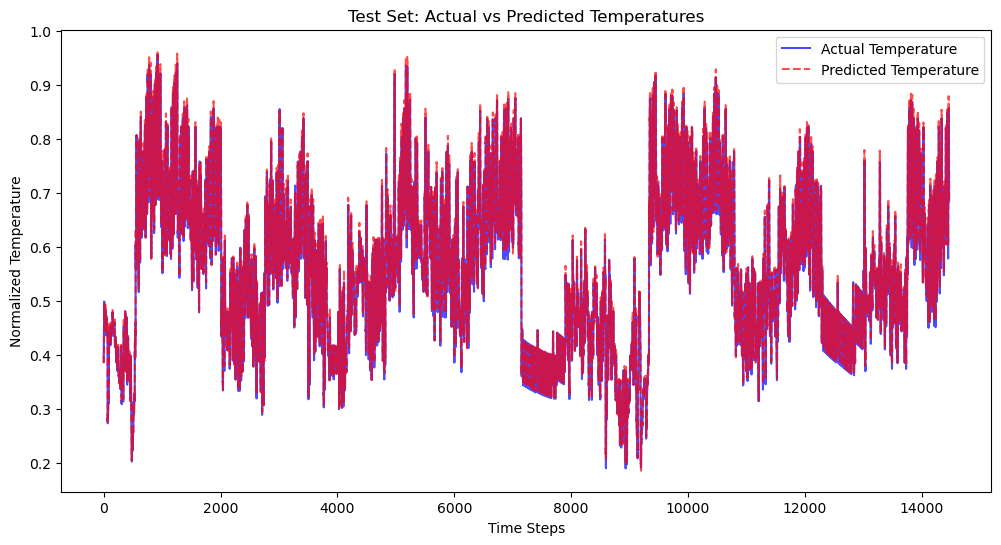

In [7]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt

# Make predictions on the test set
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Test RMSE: {rmse:.4f}")
print(f"Test MAE: {mae:.4f}")
print(f"Test R² Score: {r2:.4f}")

# Plot Predicted vs Actual Temperatures for the test period
plt.figure(figsize=(12, 6))
plt.plot(y_test, label='Actual Temperature', color='blue', alpha=0.7)
plt.plot(y_pred, label='Predicted Temperature', color='red', linestyle='--', alpha=0.7)
plt.title('Test Set: Actual vs Predicted Temperatures')
plt.xlabel('Time Steps')
plt.ylabel('Normalized Temperature')
plt.legend()
plt.show()

### Observations and Explanation:
* **Evaluation Metrics:** Evaluated the trained RNN model on unseen test data using Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), and $R^2$ score to measure prediction accuracy.
* **Graphical Comparison:** The "Predicted vs Actual" temperature plot for the test period shows how well the model tracks the actual weather patterns and trends.

7. Forecast the next 7 days of temperature using the trained model and visualize predictions vs recent historical data:

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step


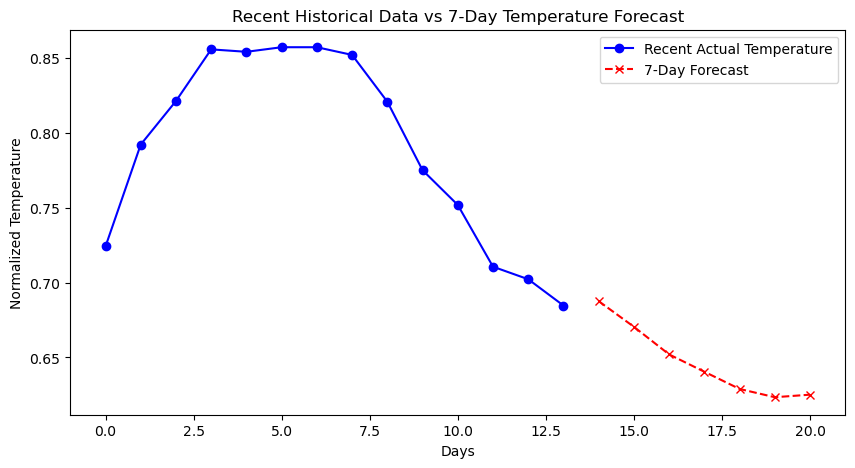

In [11]:
# Function to forecast the next 7 days recursively using the last available window from the dataset

def forecast_next_7_days(model, last_sequence, n_steps=7):
    predictions = []
    current_seq = last_sequence.copy()
    
    for _ in range(n_steps):
        # Predict the next step (shape: [1, 1])
        pred = model.predict(current_seq[np.newaxis, :, :])
        predictions.append(pred[0, 0])
        
        # Update the sequence by rolling and inserting the new prediction
        # (Assuming temperature is the first feature index 0)
        new_row = current_seq[-1].copy()
        new_row[0] = pred[0, 0]
        current_seq = np.vstack([current_seq[1:], new_row])
        
    return np.array(predictions)

# Get the last sequence from the test set to forecast ahead
last_window = X_test[-1]
forecasted_temps = forecast_next_7_days(model, last_window, n_steps=7)

# Visualize recent historical data vs 7-day forecast
plt.figure(figsize=(10, 5))
plt.plot(range(len(y_test[-14:])), y_test[-14:], label='Recent Actual Temperature', marker='o', color='blue')
plt.plot(range(14, 14 + 7), forecasted_temps, label='7-Day Forecast', marker='x', color='red', linestyle='--')
plt.title('Recent Historical Data vs 7-Day Temperature Forecast')
plt.xlabel('Days')
plt.ylabel('Normalized Temperature')
plt.legend()
plt.show()

### Observations and Explanation:
* **Recursive Forecasting:** Used the trained RNN model to predict future weather values iteratively for the next 7 days based on the most recent historical input sequence.
* **Visualization:** Plotted the 7-day forecast alongside recent historical data to clearly visualize the predicted temperature trajectory.